In [ ]:
from data_pipelines.FKB_data_pipeline import load_fkb_data, filter_fkb_data
from data_pipelines.segmentation import segment_rooftiles, snap_geometries

fkb_data = load_fkb_data("data/Basisdata_5001_Trondheim_5972_FKB-Bygning_GML.gml")

filtered_fkb = filter_fkb_data(fkb_data, "data/sample_roofdata_50")

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

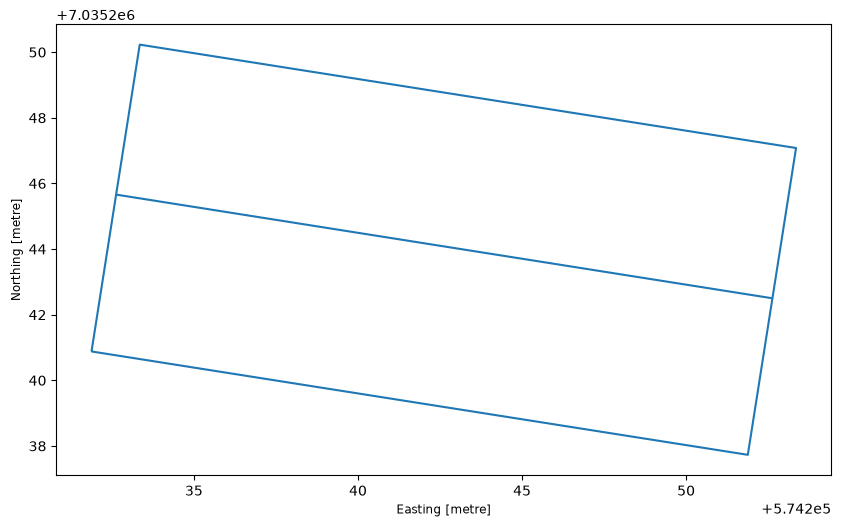

In [5]:
import matplotlib.pyplot as plt
data = filtered_fkb.get('182130478.laz')
takkant = data["takkant"]
mone, bygg = snap_geometries(
    data["monelinje"],
    data["bygningslinje"],
    data["takkant"].geometry,
    0.3,
)
fig, ax = plt.subplots(figsize=(10, 10))

takkant.plot(
    ax=ax
)
mone.plot(
    ax=ax
)


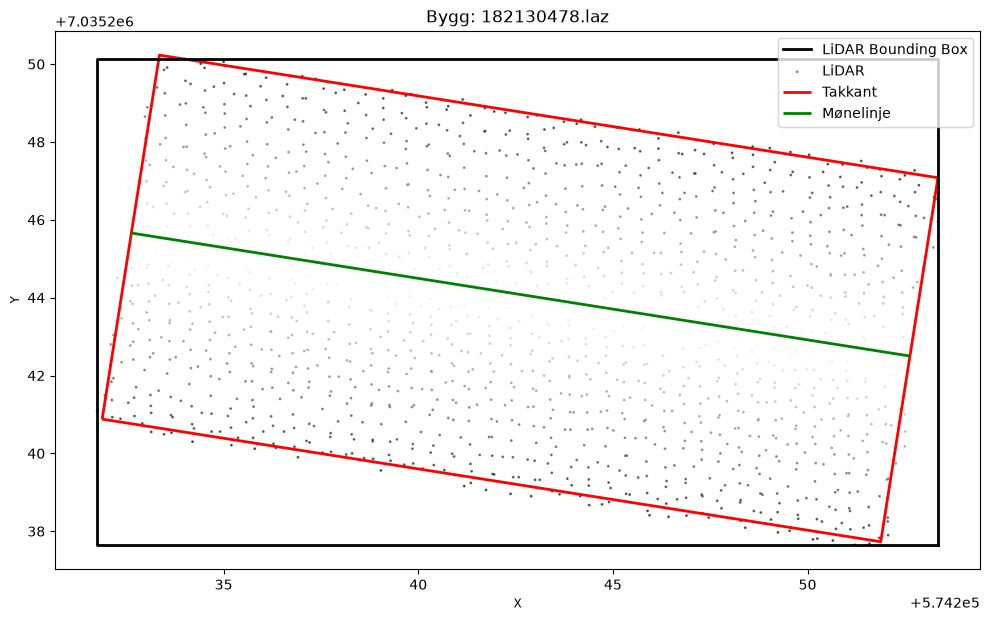

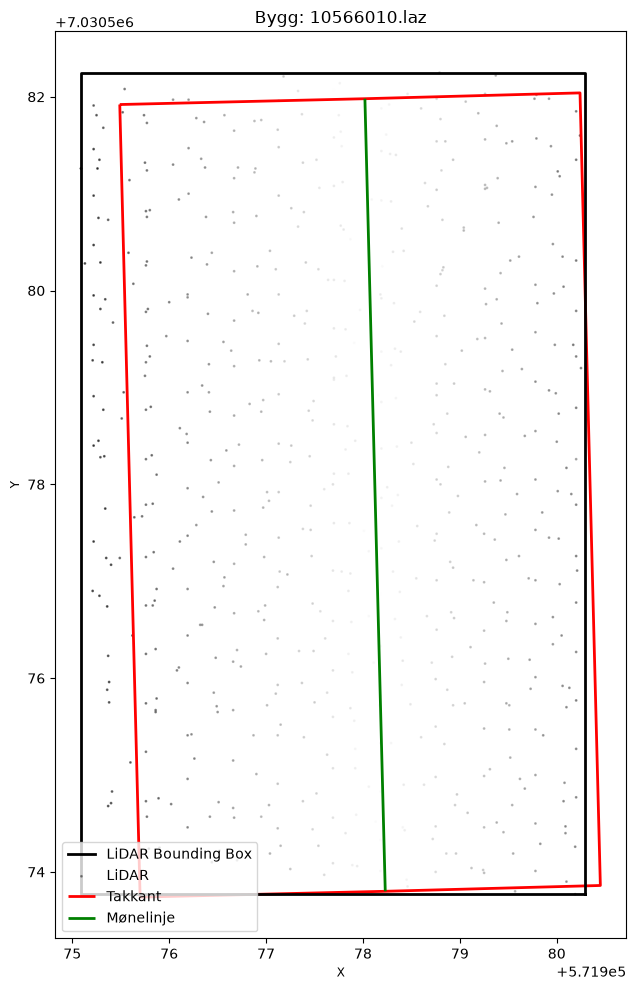

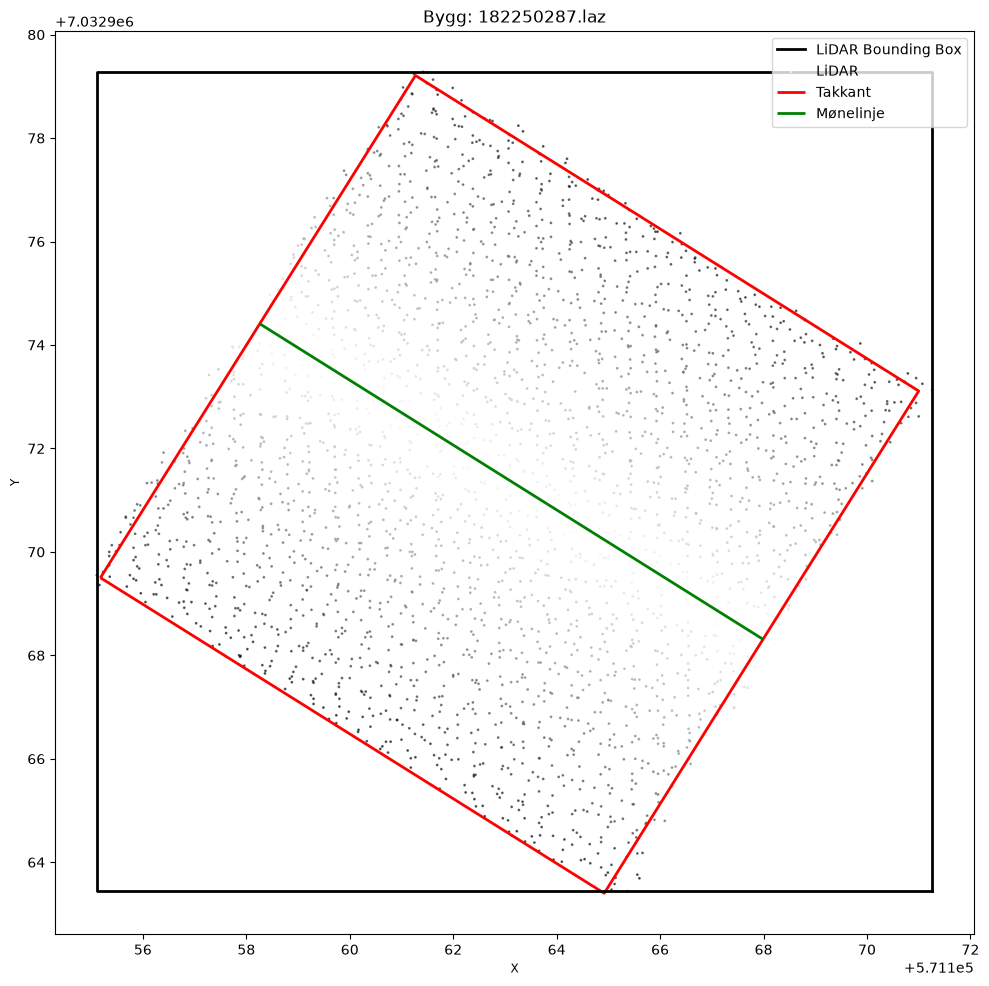

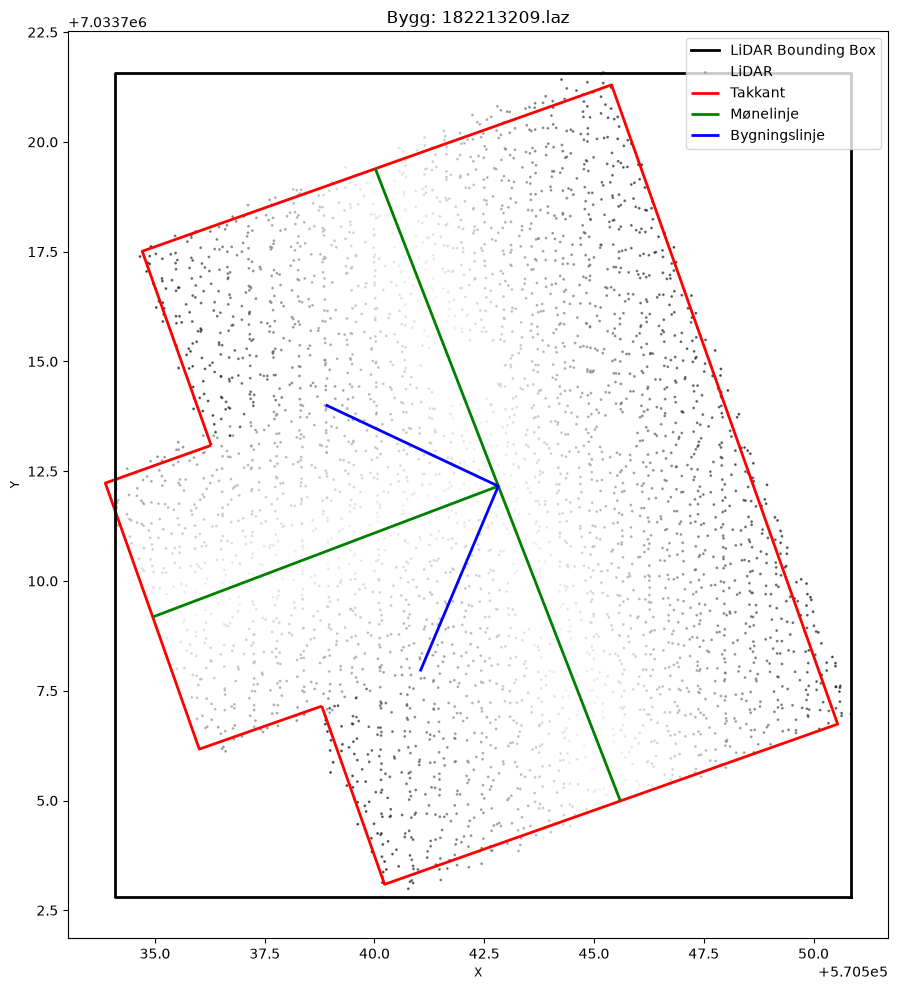

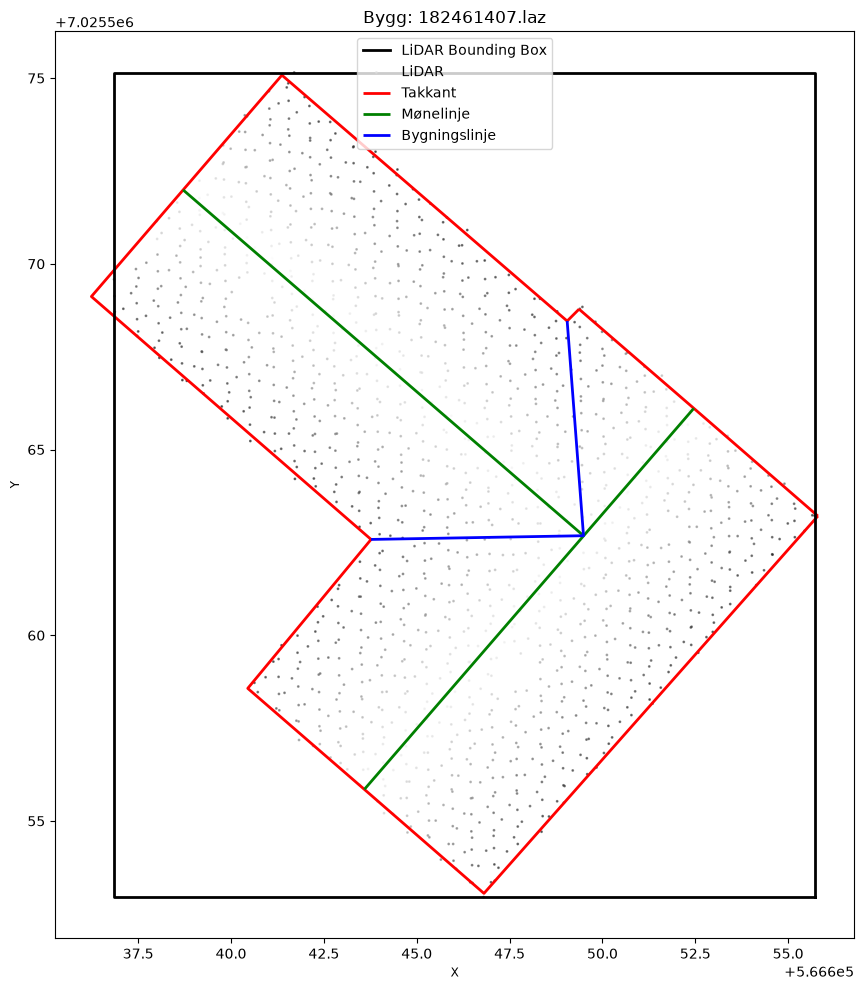

...

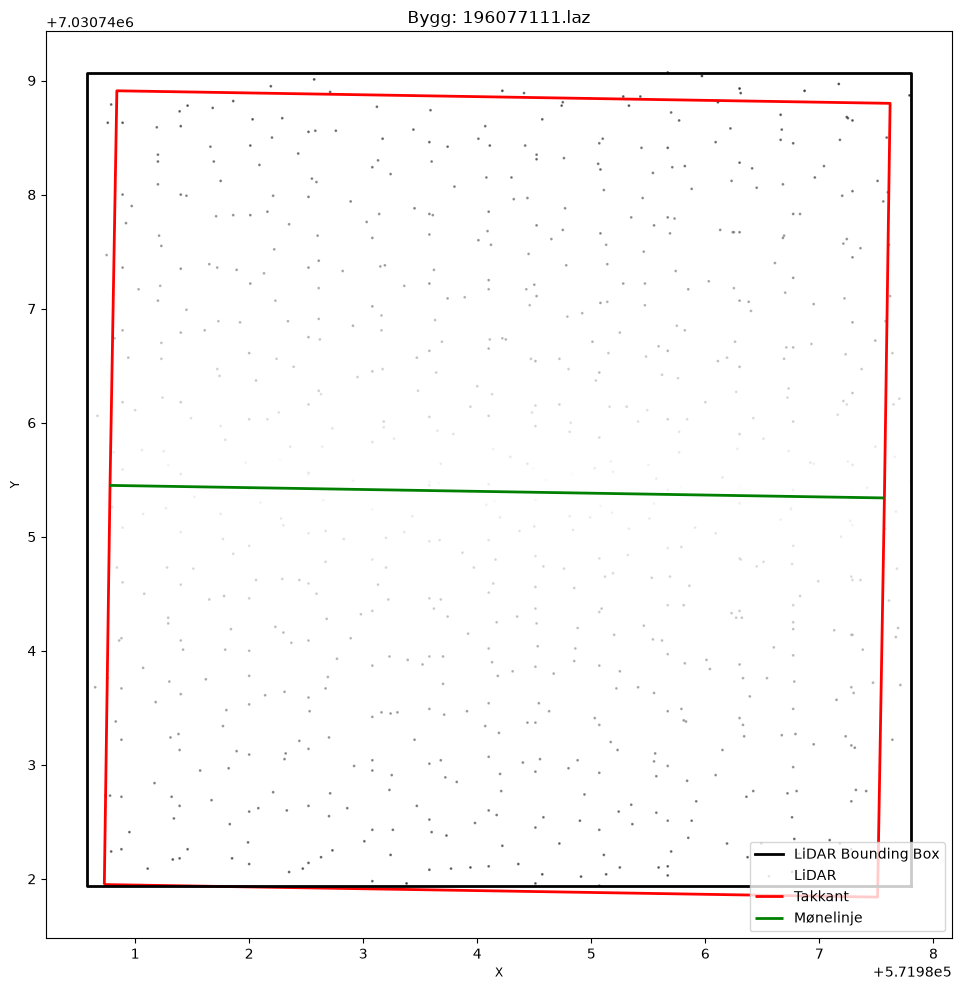

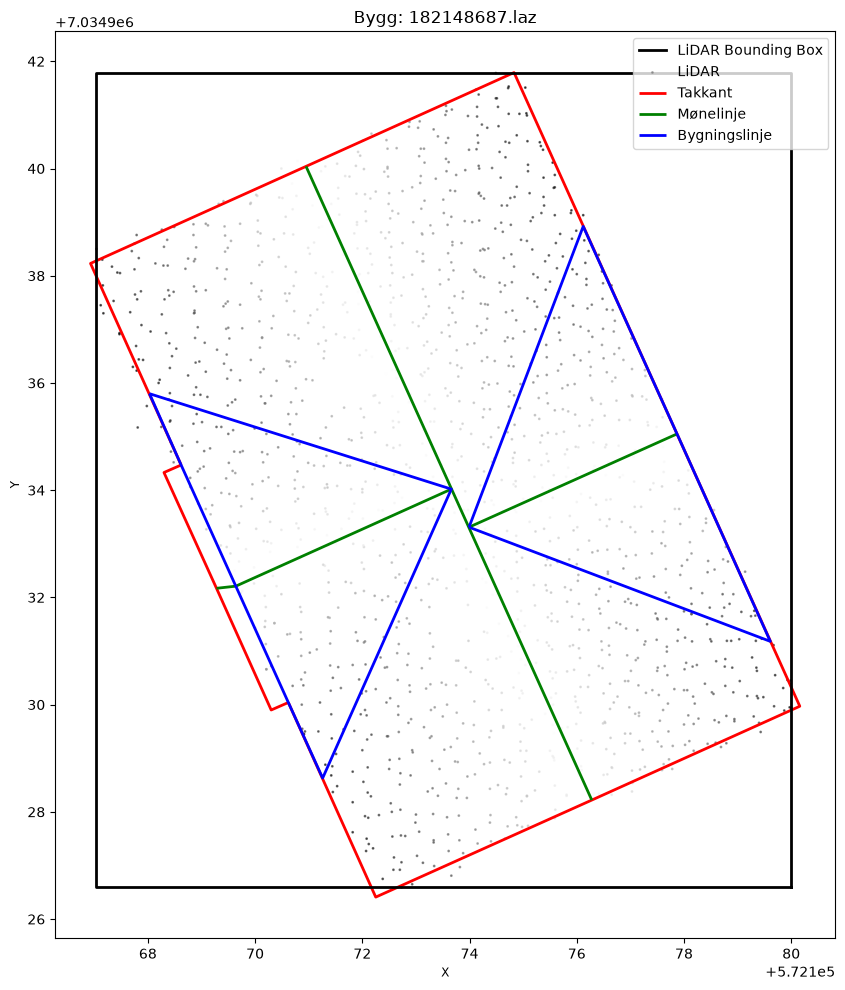

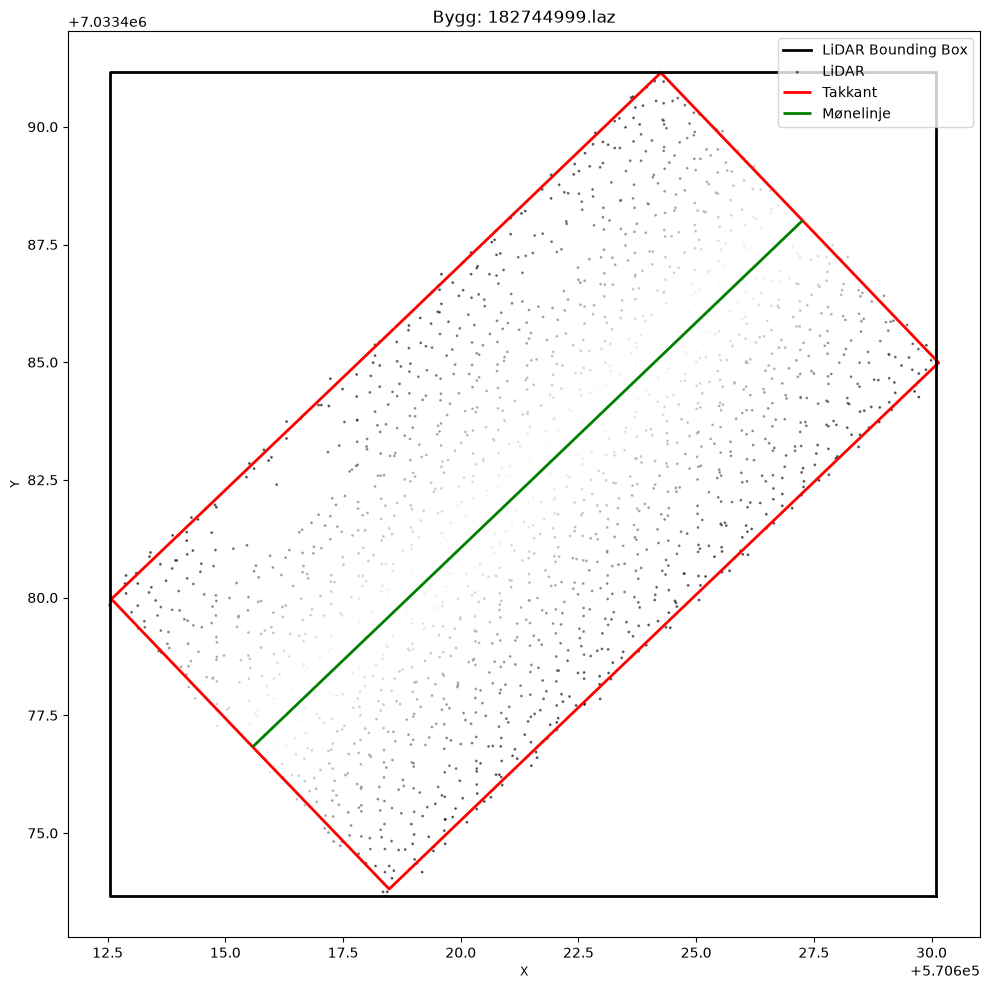

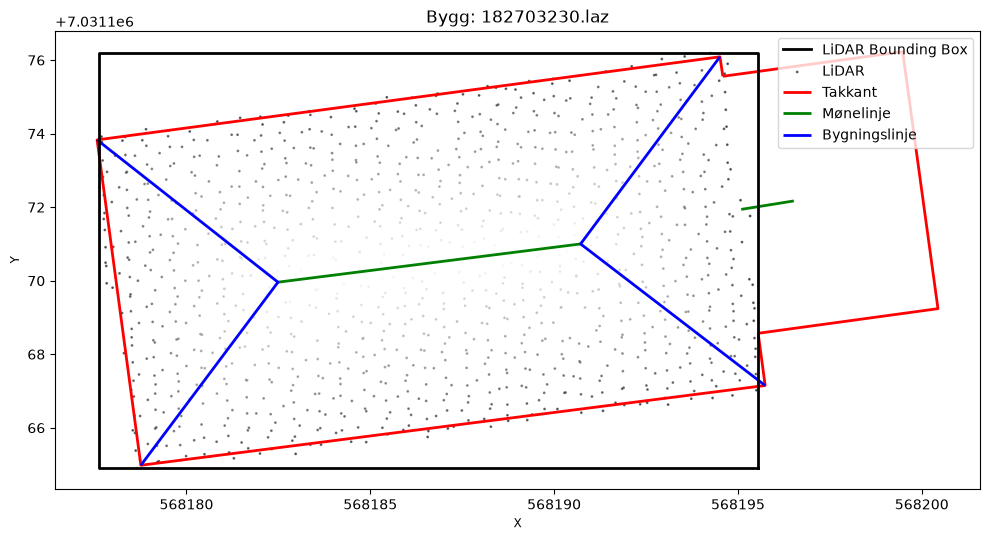

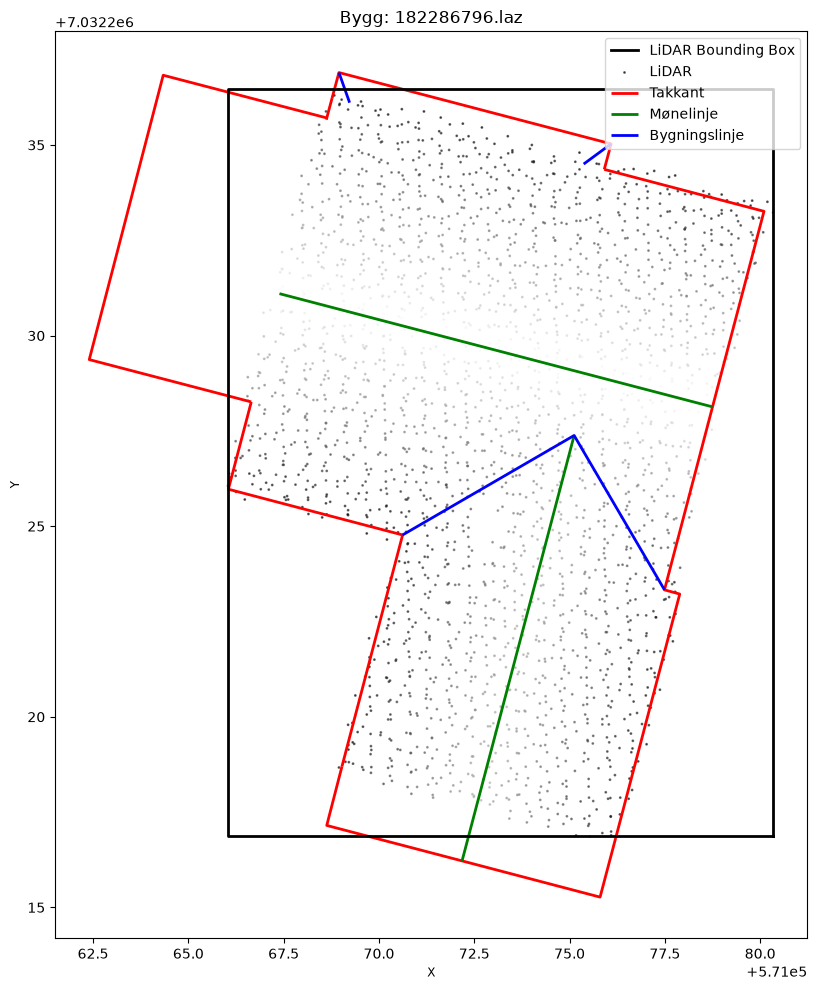

In [3]:
import matplotlib.pyplot as plt

for key, value in filtered_fkb.items():
    lidar = value.get("lidar")
    if lidar is None:
        continue
    bbox = value.get("bbox")
    monelinje = value["monelinje"]
    takkant = value["takkant"]
    bygningslinje = value["bygningslinje"]

    fig, ax = plt.subplots(figsize=(10, 10))

    ax.plot(
        *bbox.exterior.xy,
        color="black",
        linewidth=2,
        label="LiDAR Bounding Box",
        zorder=5,
    )
    
    ax.scatter(
        lidar.x,
        lidar.y,
        c=lidar.z,
        s=1,
        cmap="gray",
        alpha=0.6,
        label="LiDAR",
        zorder=1,
    )

    # FKB-linjer
    if not takkant.empty:
        takkant.plot(
            ax=ax,
            color="red",
            linewidth=2,
            label="Takkant",
            zorder=2,
        )

    if not monelinje.empty:
        monelinje.plot(
            ax=ax,
            color="green",
            linewidth=2,
            label="Mønelinje",
            zorder=3,
        )

    if not bygningslinje.empty:
        bygningslinje.plot(
            ax=ax,
            color="blue",
            linewidth=2,
            label="Bygningslinje",
            zorder=4,
        )

    ax.set_title(f"Bygg: {key}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal")
    ax.legend()

    plt.tight_layout()
    plt.show()
   

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

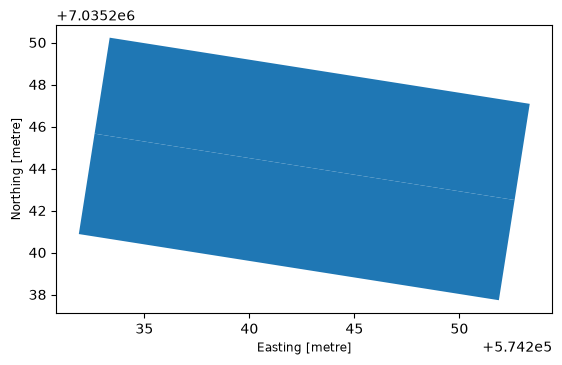

In [15]:
data = filtered_fkb.get('182130478.laz')

segment = segmentert = segment_rooftiles(
            monelinje=data["monelinje"],
            takkant=data["takkant"],
            bygningslinje=data["bygningslinje"],
            tolerance=0.3,
        )
segment.plot()

OK 182130478.laz: 2 takflater
OK 10566010.laz: 2 takflater
OK 182250287.laz: 2 takflater
OK 182213209.laz: 2 takflater
OK 182461407.laz: 4 takflater
OK 182380105.laz: 2 takflater
OK 182251615.laz: 4 takflater
OK 182221864.laz: 4 takflater
OK 182486507.laz: 4 takflater
OK 182251399.laz: 4 takflater
OK 10565839.laz: 2 takflater
OK 182307580.laz: 4 takflater
OK 182294063.laz: 8 takflater
OK 10529360.laz: 2 takflater
OK 182292761.laz: 4 takflater
OK 10479436.laz: 4 takflater
OK 182311324.laz: 2 takflater
OK 182217581.laz: 2 takflater
OK 182461857.laz: 5 takflater
OK 182379476.laz: 1 takflater
OK 300426167.laz: 2 takflater
OK 182218669.laz: 2 takflater
OK 182274798.laz: 6 takflater
OK 10529379.laz: 2 takflater
OK 182172235.laz: 13 takflater
OK 21028401.laz: 7 takflater
OK 10468485.laz: 4 takflater
OK 182390828.laz: 4 takflater
OK 182278629.laz: 4 takflater
OK 182286044.laz: 2 takflater
OK 10444144.laz: 4 takflater
OK 182337978.laz: 1 takflater
OK 182314838.laz: 2 takflater
OK 182280240.laz:

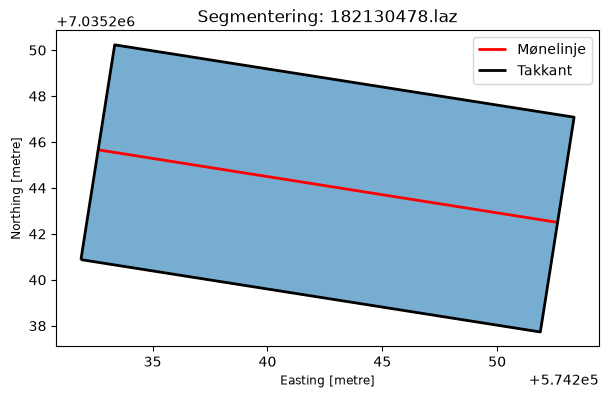

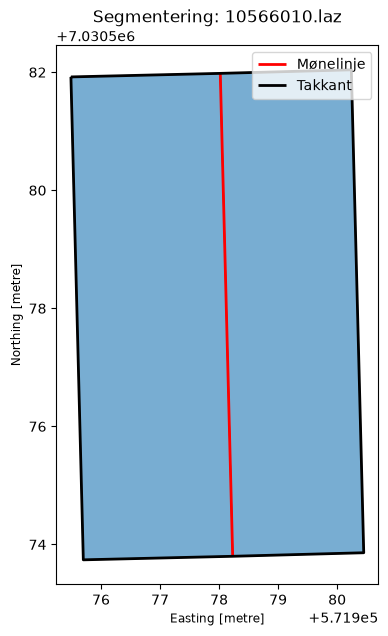

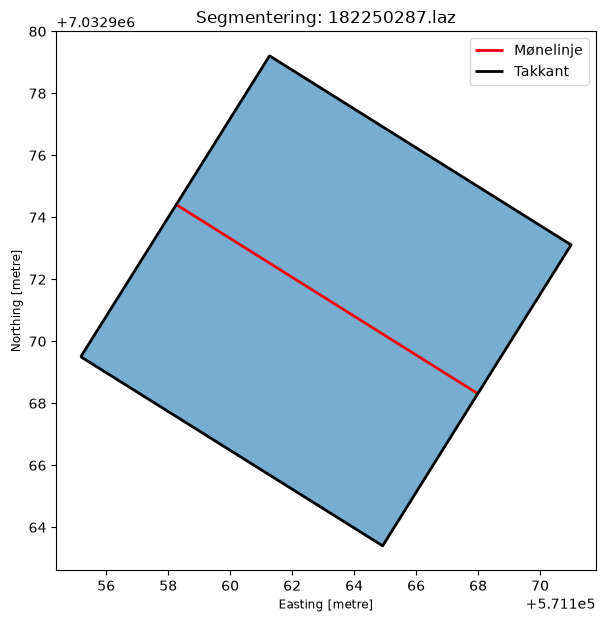

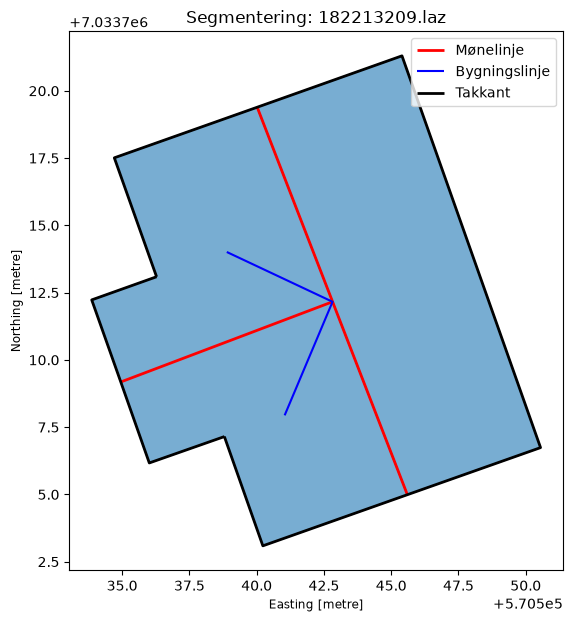

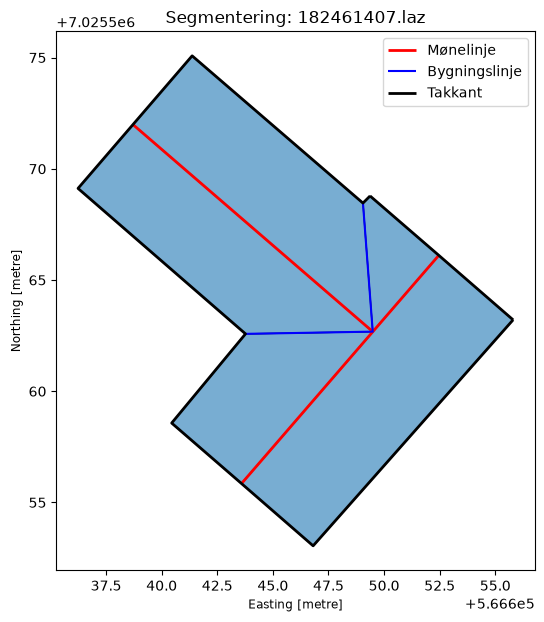

...

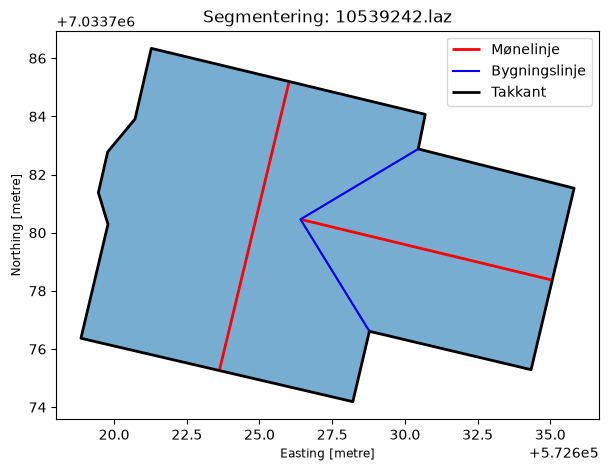

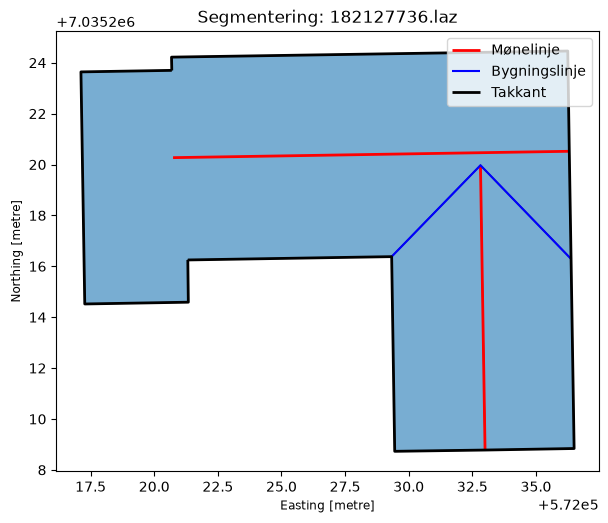

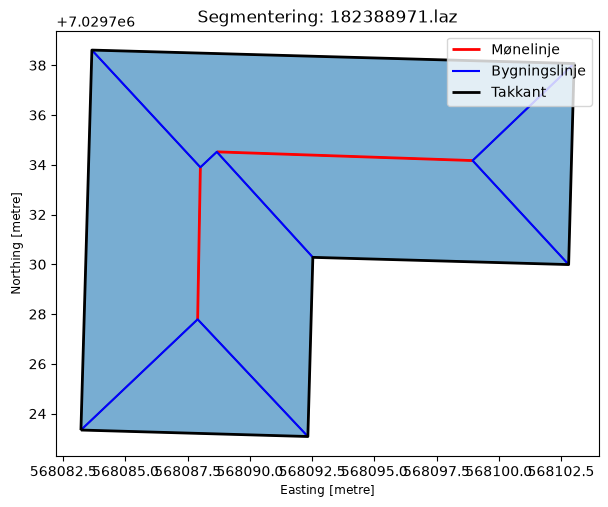

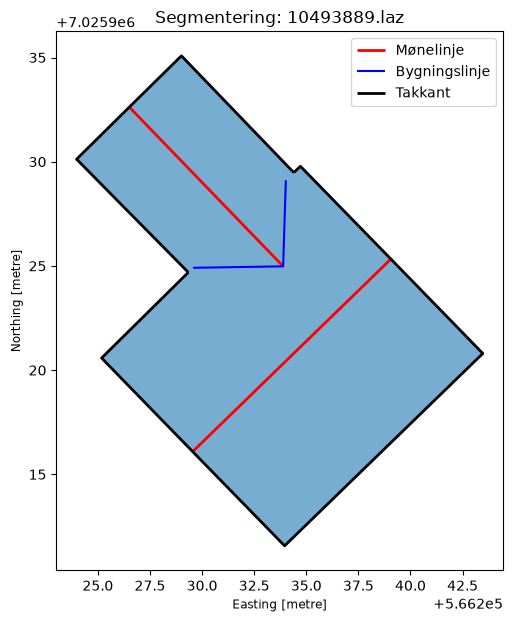

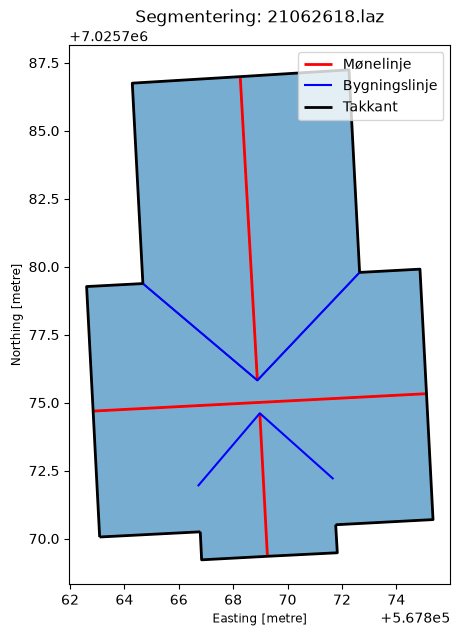

10519144.laz: ingen takflater å vise


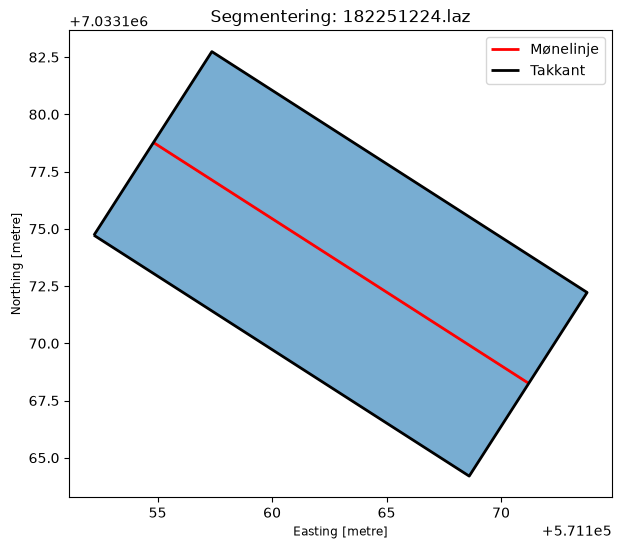

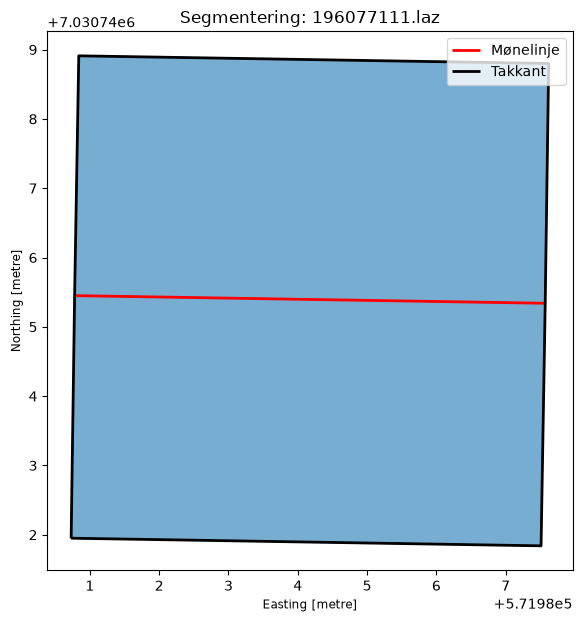

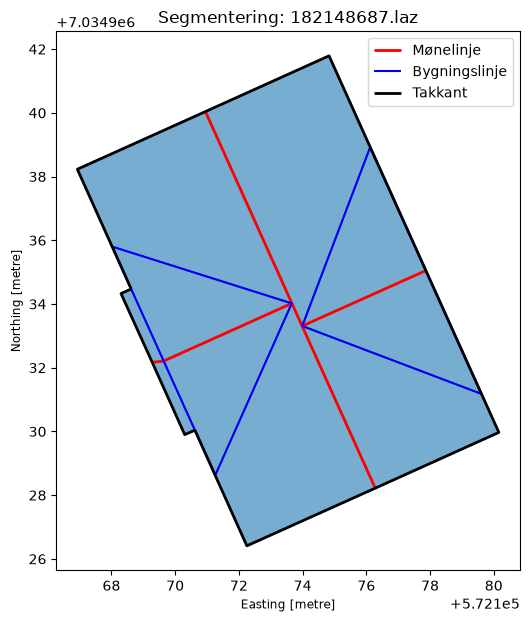

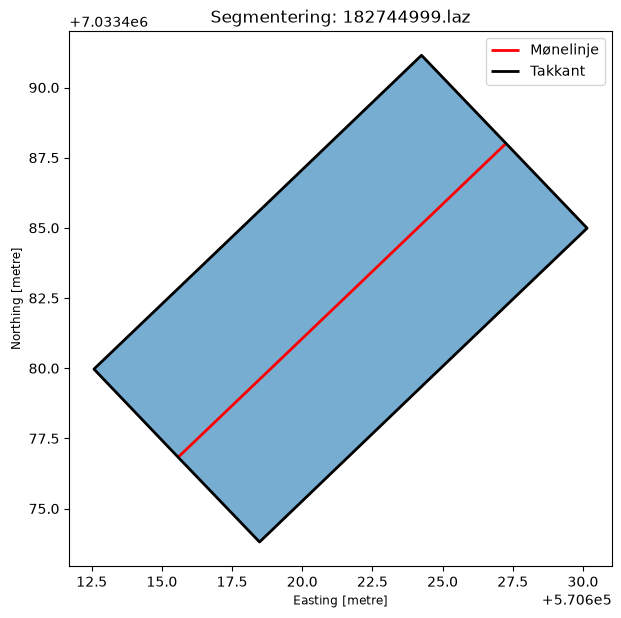

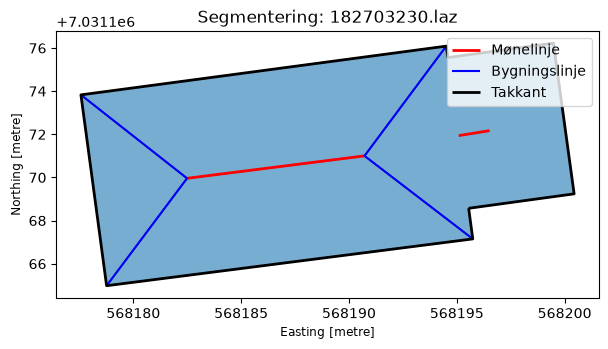

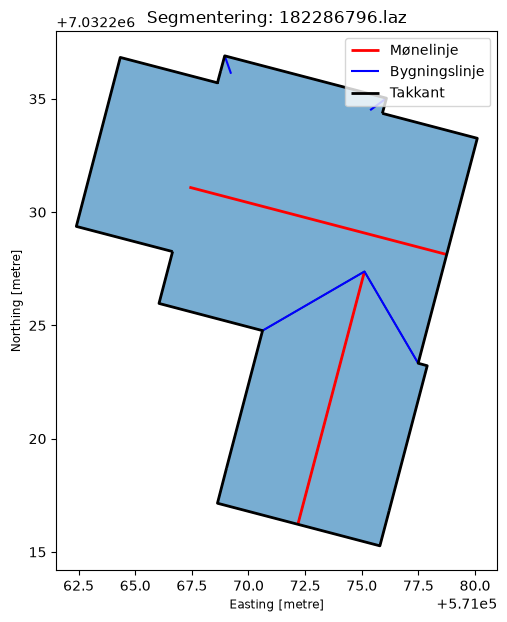

In [9]:
# Test segmentering for alle LAZ-filer i filtered_fkb
import geopandas as gpd
import matplotlib.pyplot as plt

segmentert_per_laz = {}
feil = {}

for laz_fil, fkb_data in filtered_fkb.items():
    try:
        segmentert = segment_rooftiles(
            monelinje=fkb_data["monelinje"],
            takkant=fkb_data["takkant"],
            bygningslinje=fkb_data["bygningslinje"],
            tolerance=0.3,
        )

        # Tester
        assert isinstance(segmentert, gpd.GeoSeries)
        assert segmentert.crs == fkb_data["takkant"].crs
        assert segmentert.is_valid.all()

        segmentert_per_laz[laz_fil] = segmentert
        print(f"OK {laz_fil}: {len(segmentert)} takflater")

    except Exception as error:
        feil[laz_fil] = error
        print(f"FEIL {laz_fil}: {type(error).__name__}: {error}")

print(f"\nResultat: {len(segmentert_per_laz)} OK, {len(feil)} feil")

assert not feil, f"Segmentering feilet for: {list(feil)}"

# Vis resultatene
for laz_fil, segmentert in segmentert_per_laz.items():
    if segmentert.empty:
        print(f"{laz_fil}: ingen takflater å vise")
        continue

    fkb_data = filtered_fkb[laz_fil]

    fig, ax = plt.subplots(figsize=(7, 7))

    segmentert.plot(
        ax=ax,
        alpha=0.6,
        edgecolor="black",
    )

    monelinje = fkb_data.get("monelinje")
    if monelinje is not None and not monelinje.empty:
        monelinje.plot(
            ax=ax,
            color="red",
            linewidth=2,
            label="Mønelinje",
        )

    bygningslinje = fkb_data.get("bygningslinje")
    if bygningslinje is not None and not bygningslinje.empty:
        bygningslinje.plot(
            ax=ax,
            color="blue",
            linewidth=1.5,
            label="Bygningslinje",
        )

    takkant = fkb_data.get("takkant")
    if takkant is not None and not takkant.empty:
        takkant.plot(
            ax=ax,
            color="black",
            linewidth=2,
            label="Takkant",
        )

    ax.set_title(f"Segmentering: {laz_fil}")
    ax.set_aspect("equal")
    ax.legend()

    plt.show()

182130478.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


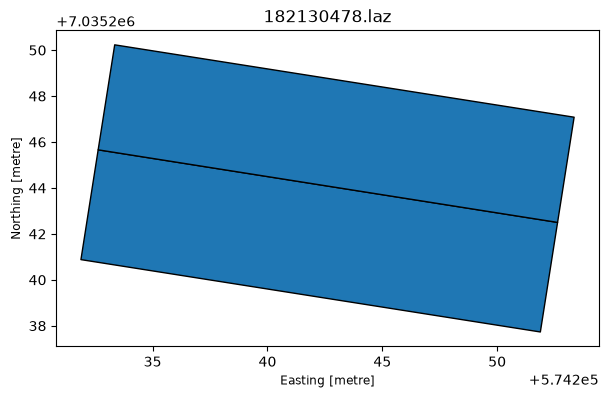

10566010.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


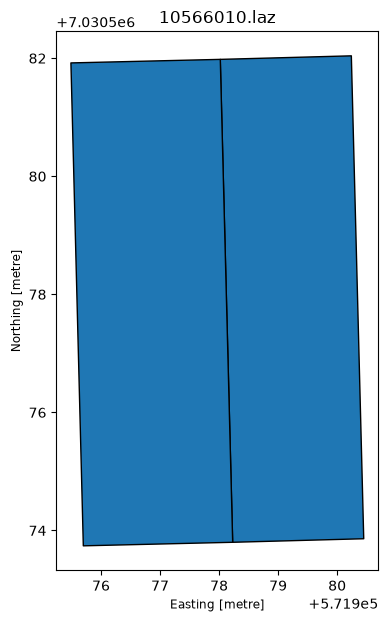

182250287.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


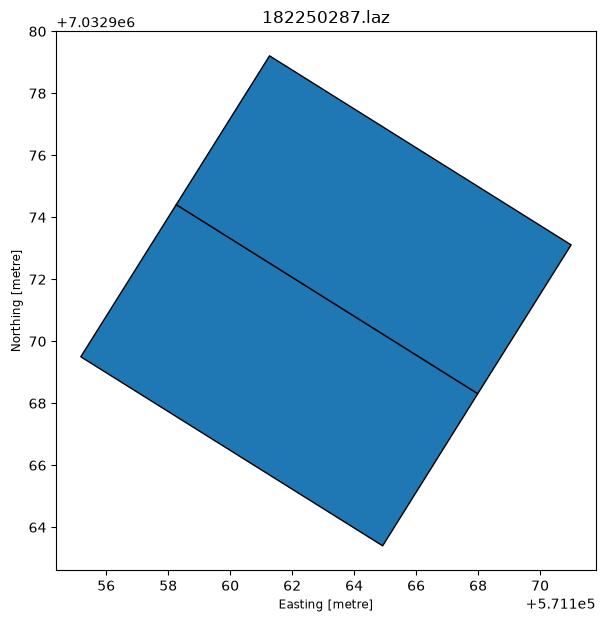

182213209.laz: 2 takflater


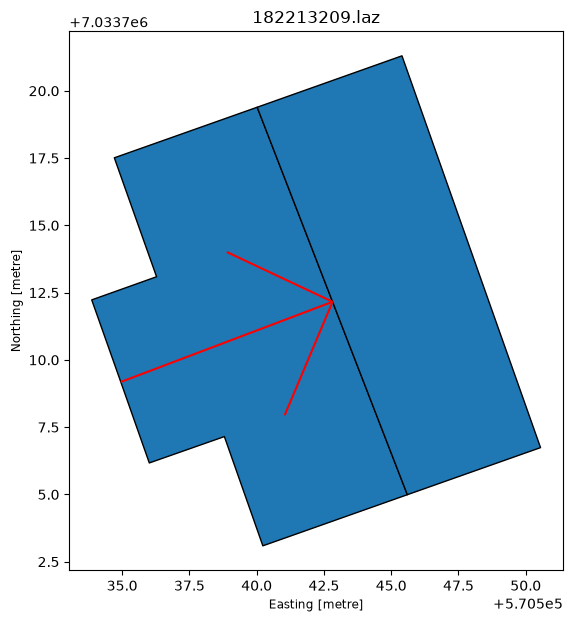

182461407.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


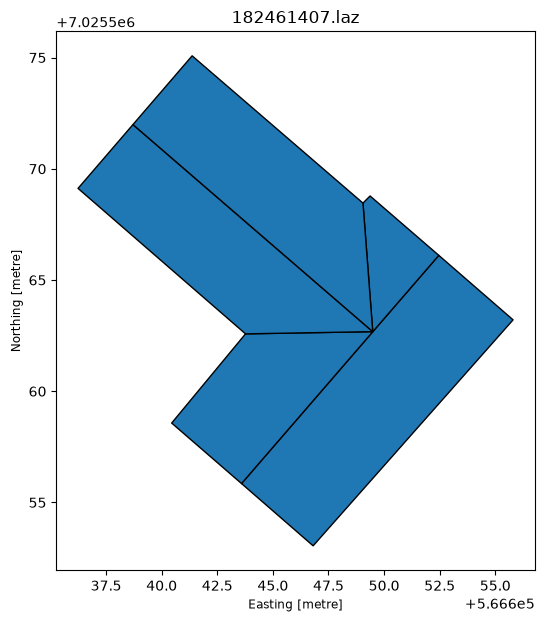

182380105.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


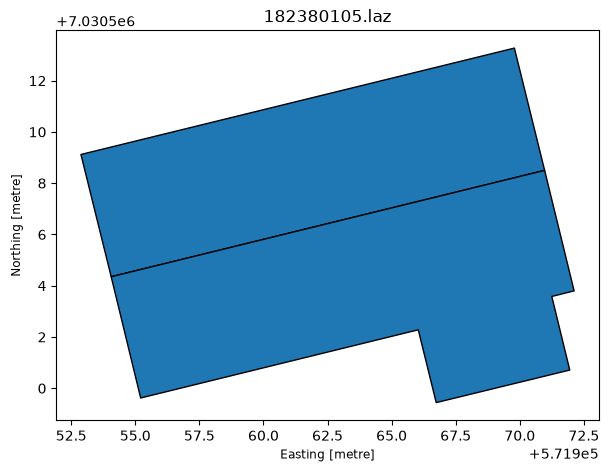

182251615.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


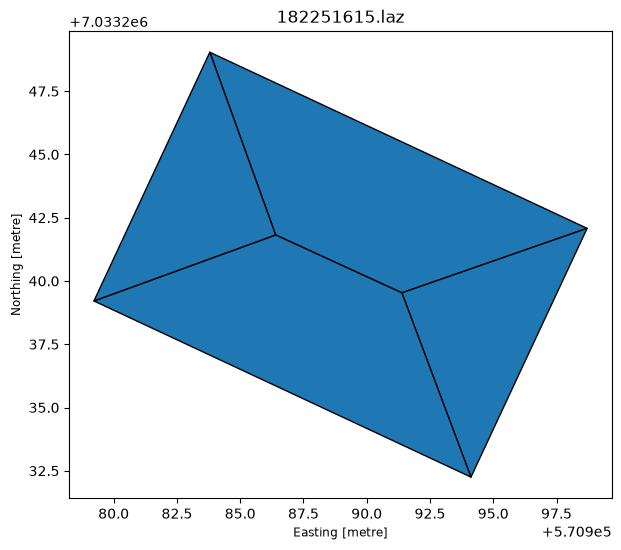

182221864.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


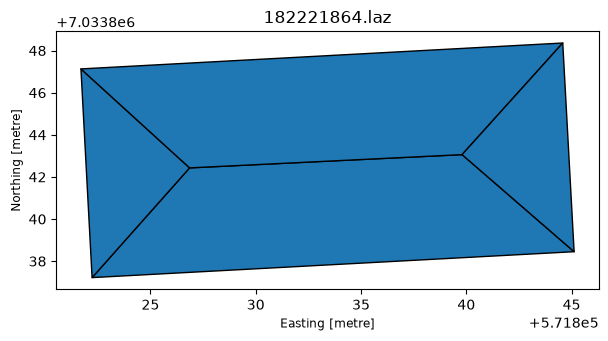

182486507.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


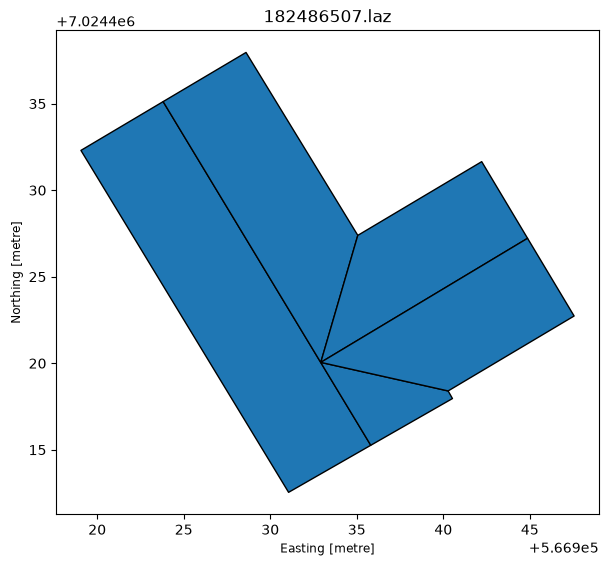

182251399.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


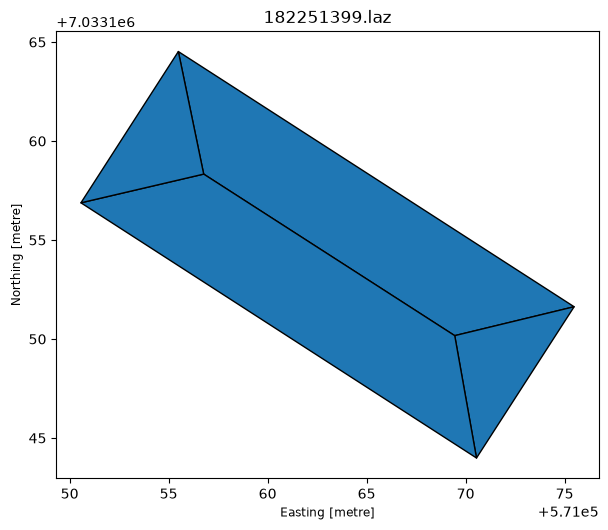

10565839.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


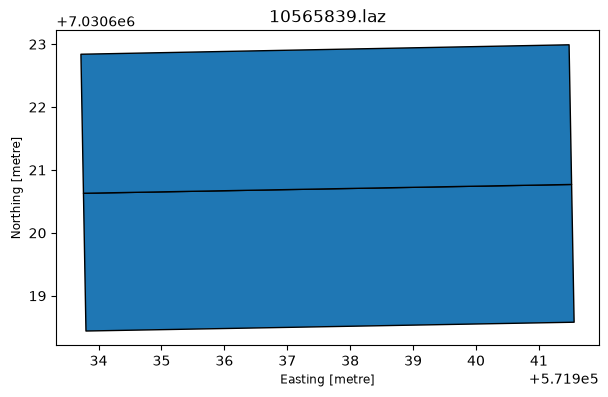

182307580.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


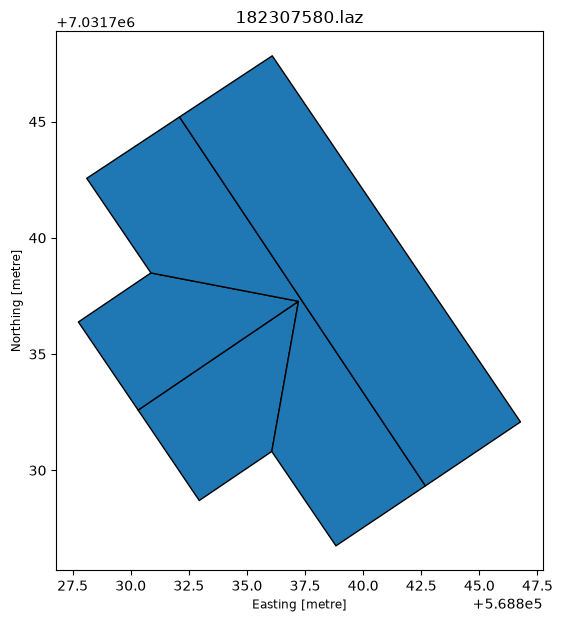

182294063.laz: 8 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


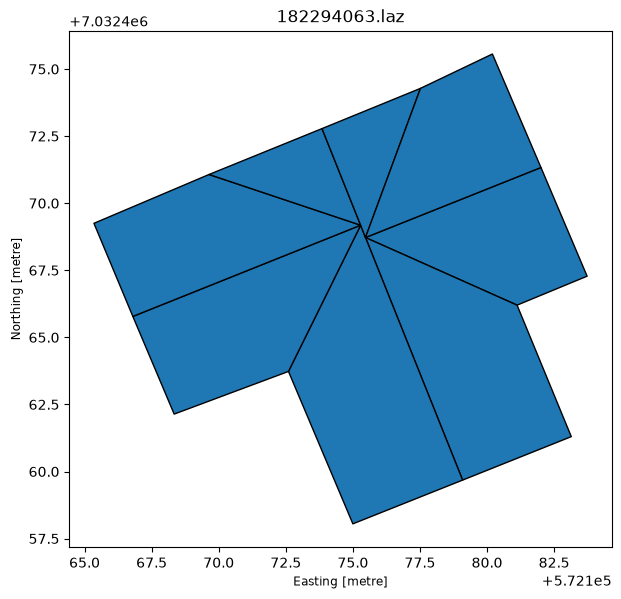

10529360.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


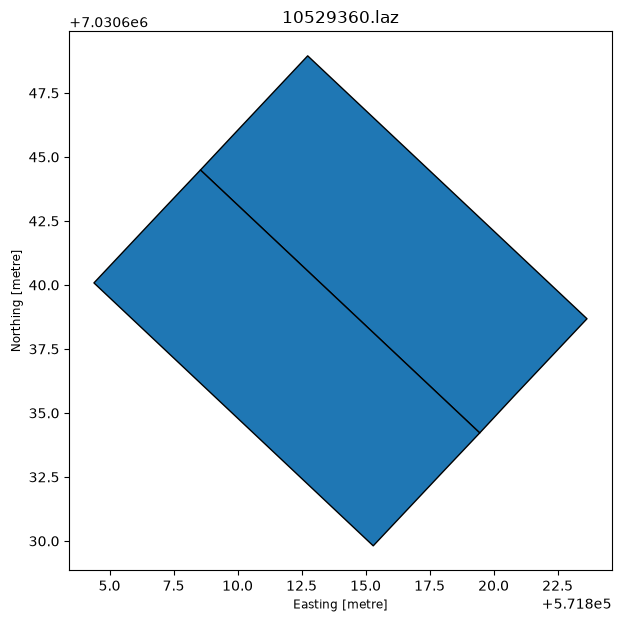

182292761.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


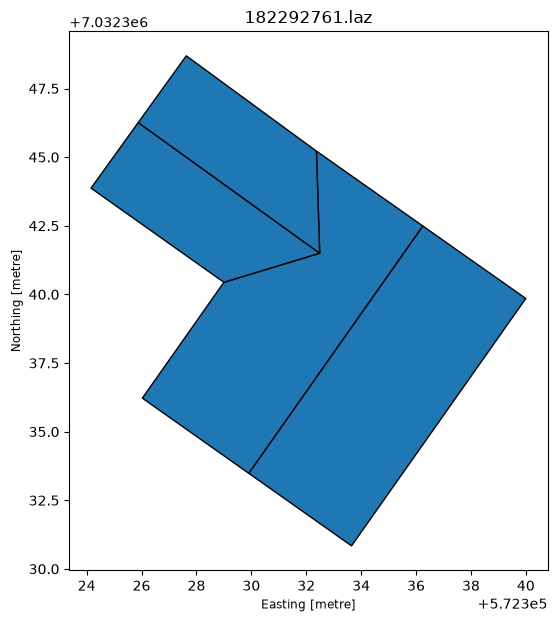

10479436.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


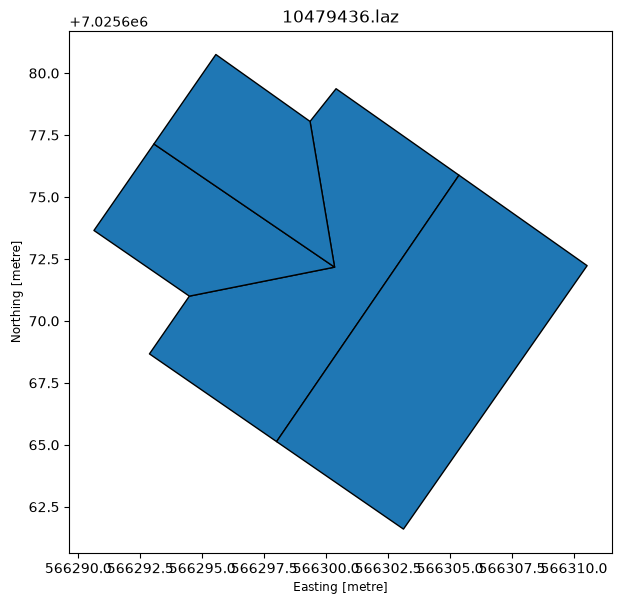

182311324.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


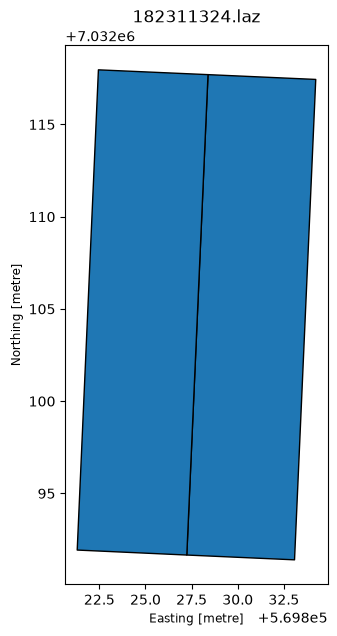

182217581.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


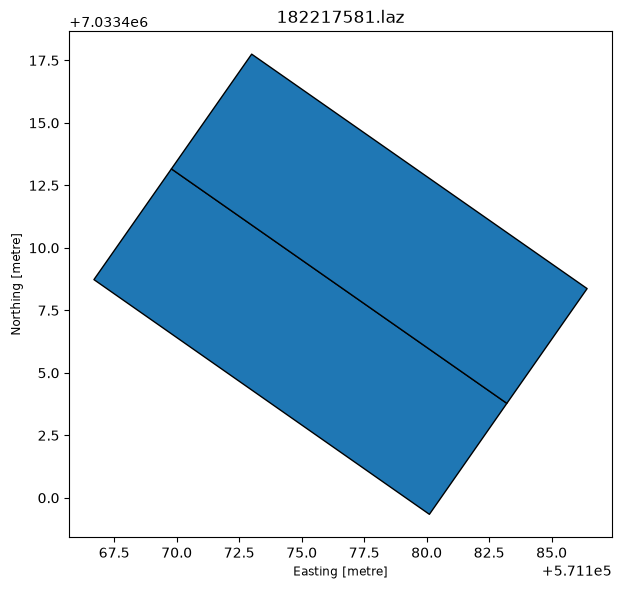

182461857.laz: 5 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


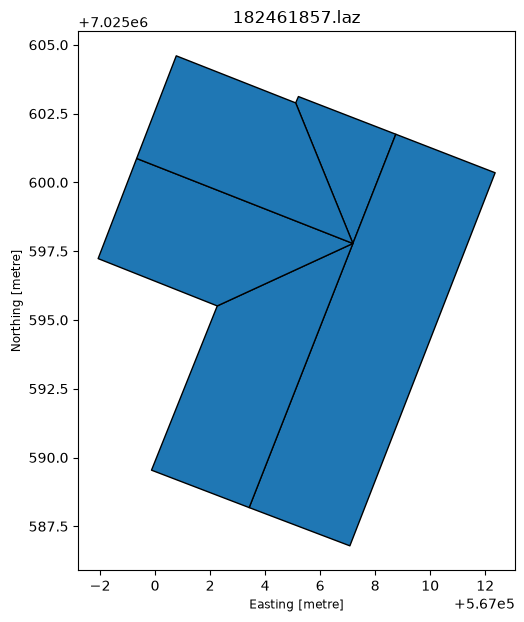

182379476.laz: 1 takflater


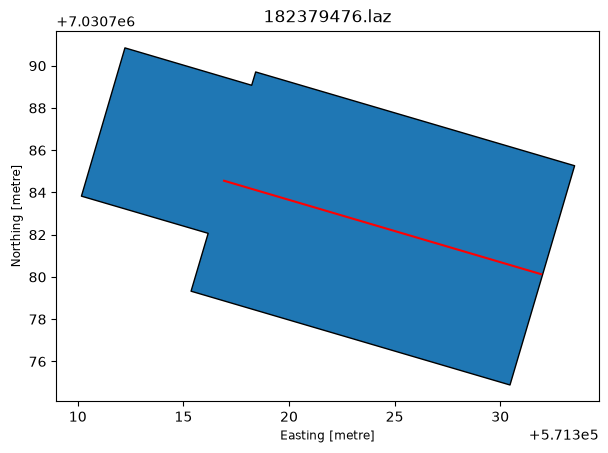

300426167.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


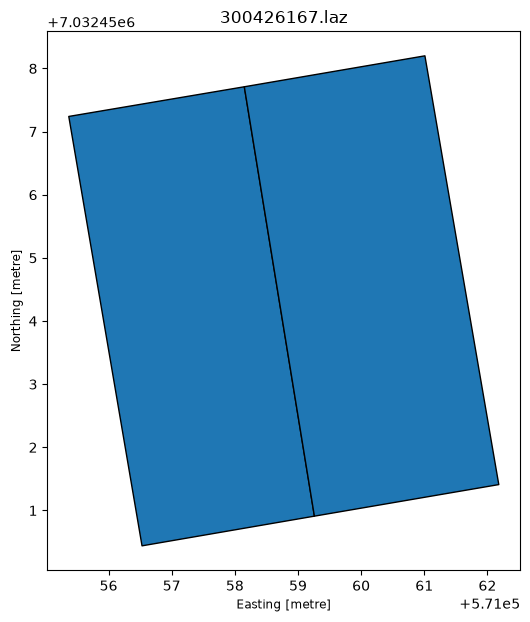

182218669.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


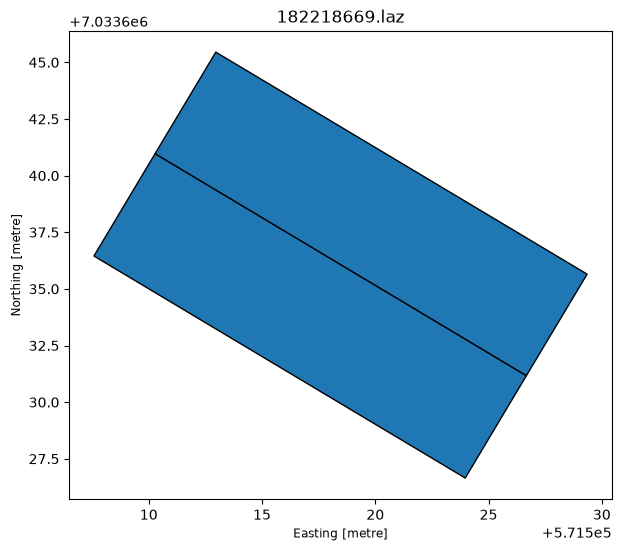

182274798.laz: 6 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


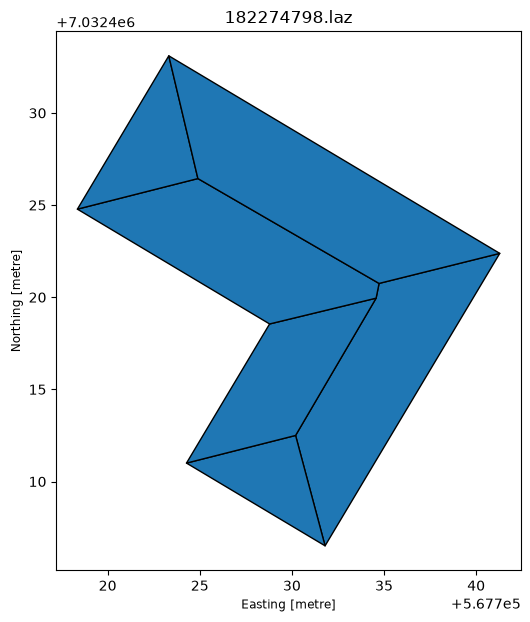

10529379.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


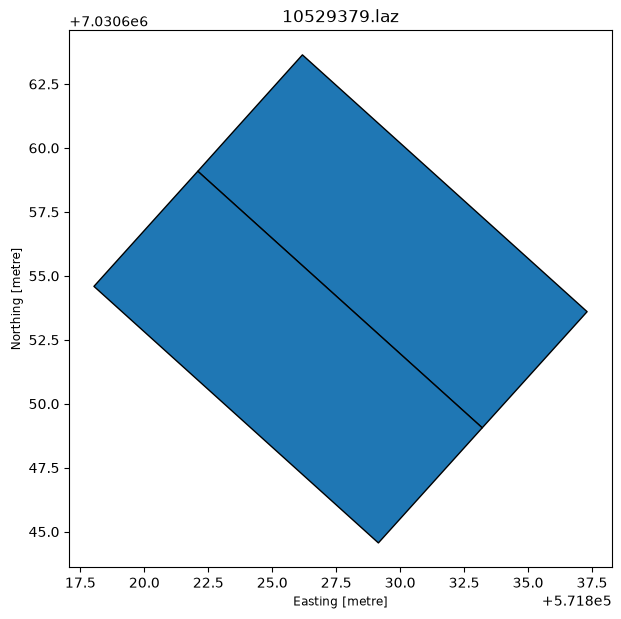

182172235.laz: 13 takflater


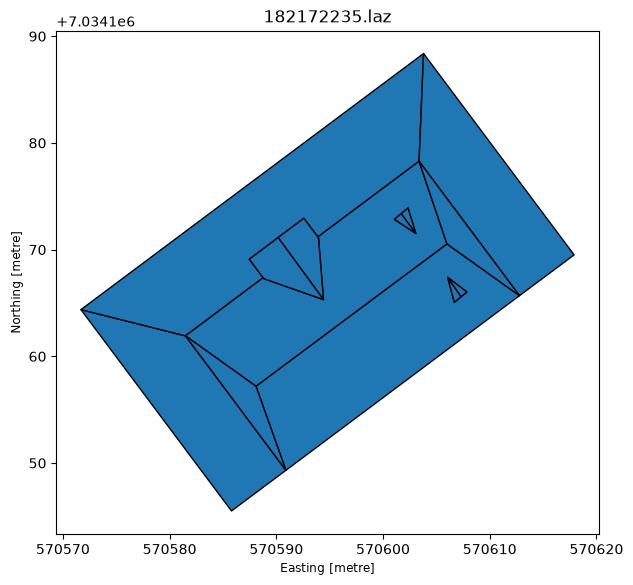

21028401.laz: 7 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


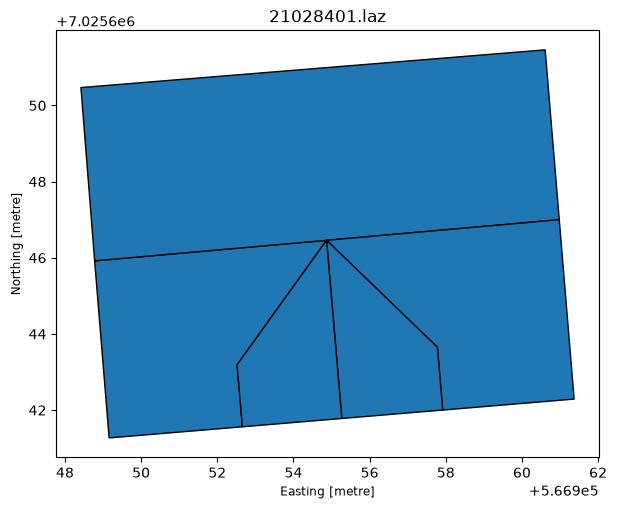

10468485.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


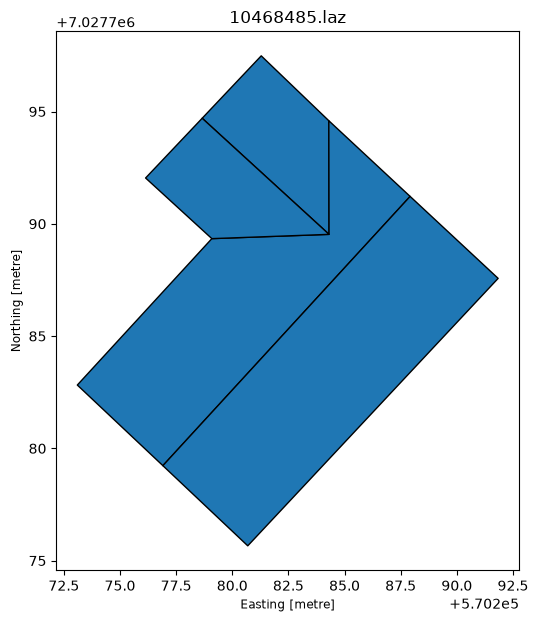

182390828.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


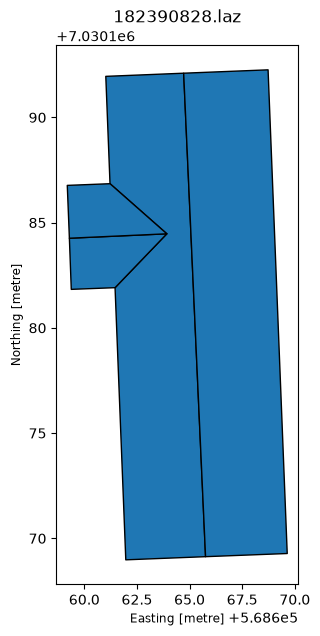

182278629.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


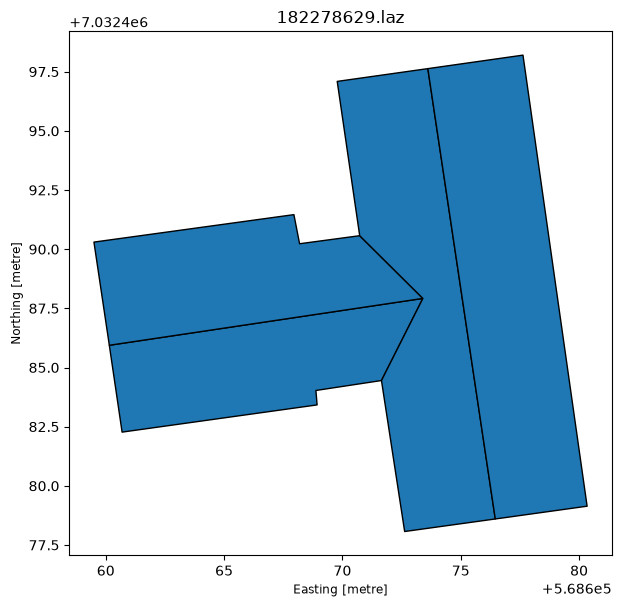

182286044.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


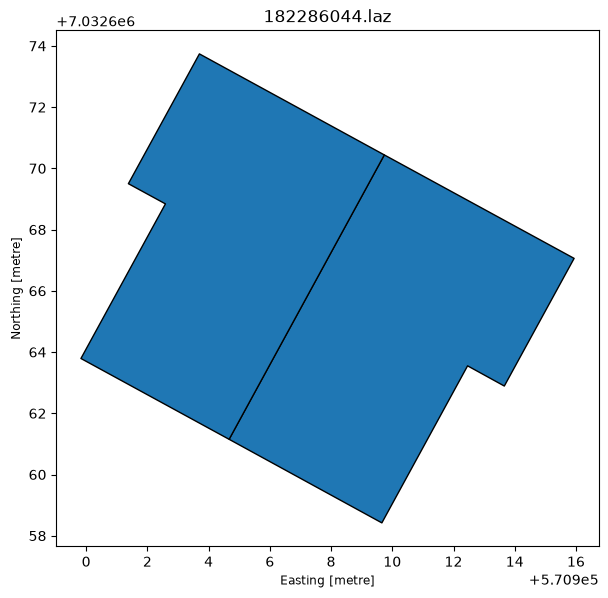

10444144.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


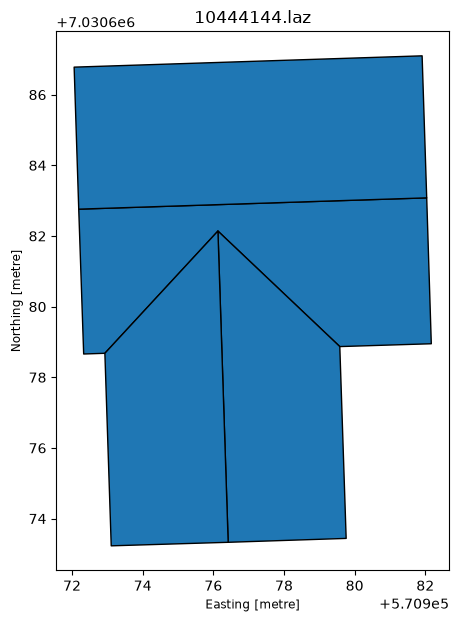

182337978.laz: 1 takflater


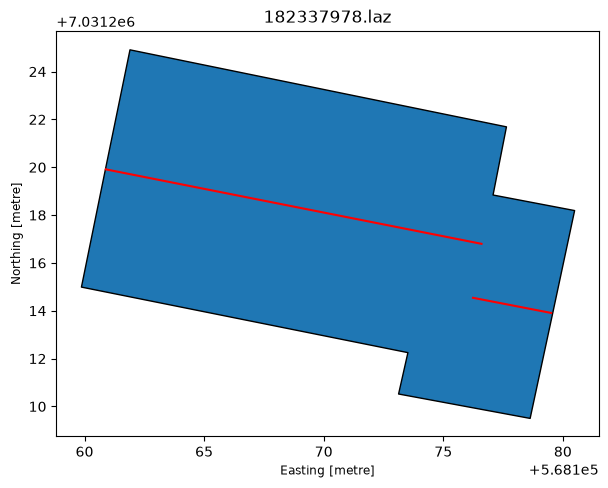

182314838.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


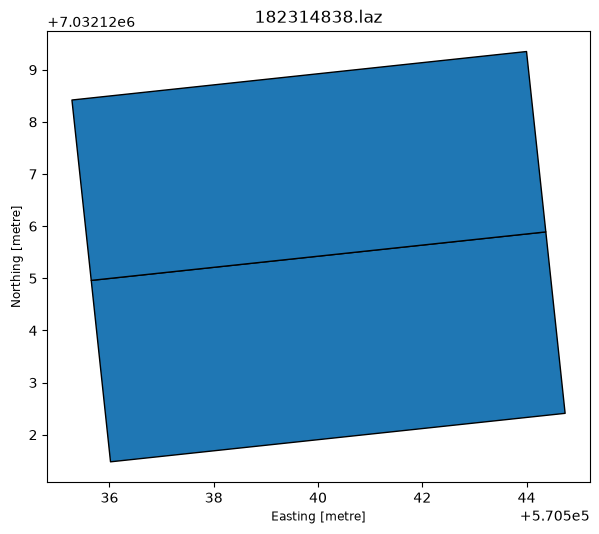

182280240.laz: 8 takflater


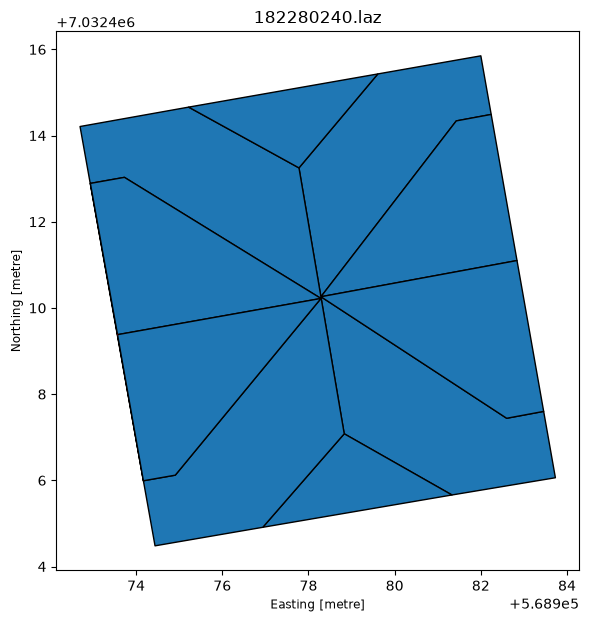

182249068.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


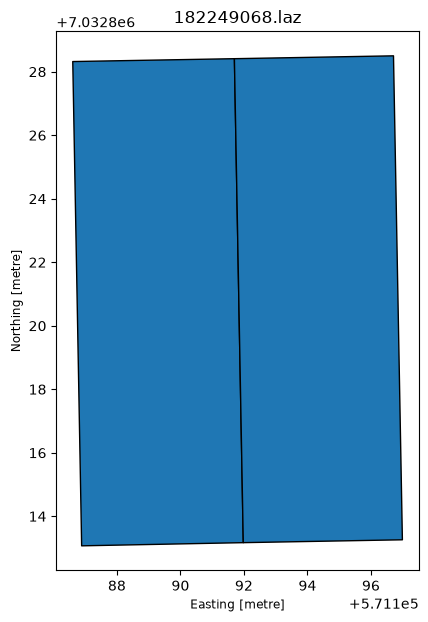

182282537.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


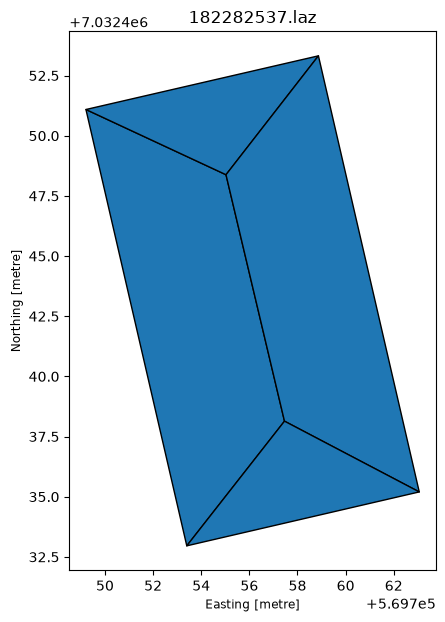

182211613.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


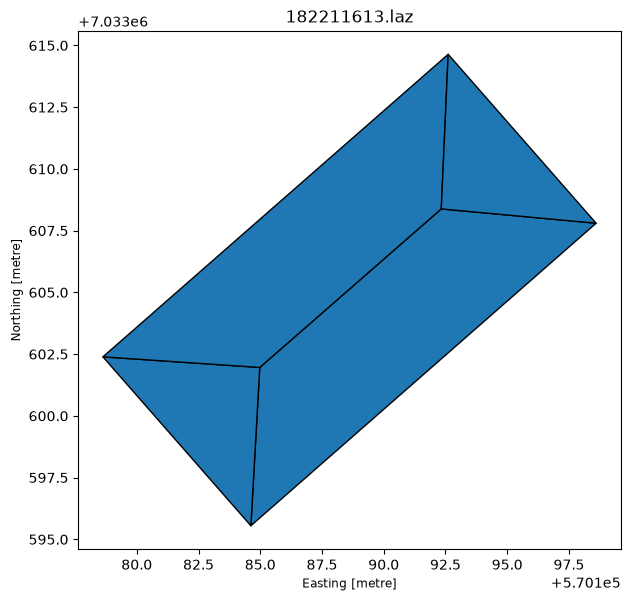

182285463.laz: 3 takflater


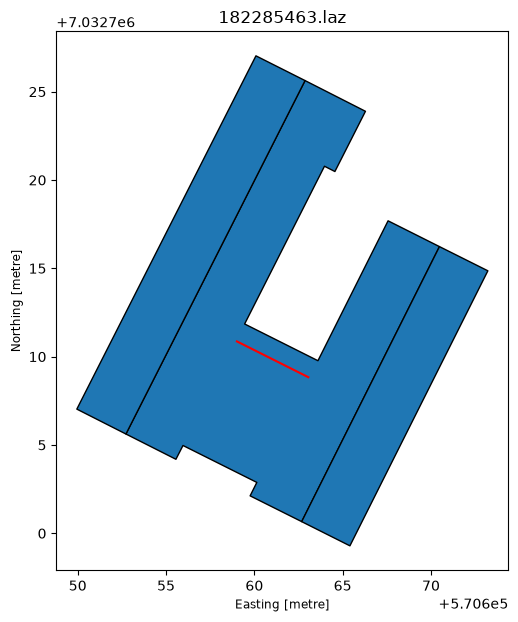

10539242.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


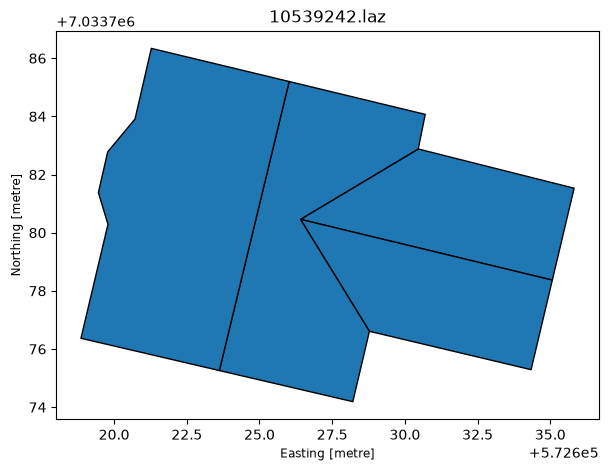

182127736.laz: 3 takflater


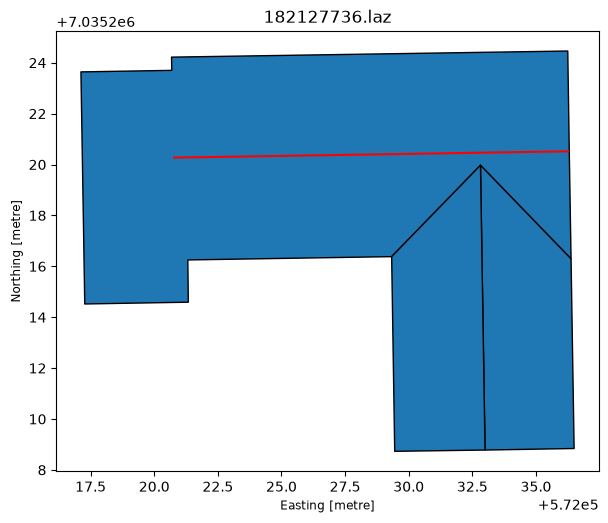

182388971.laz: 6 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


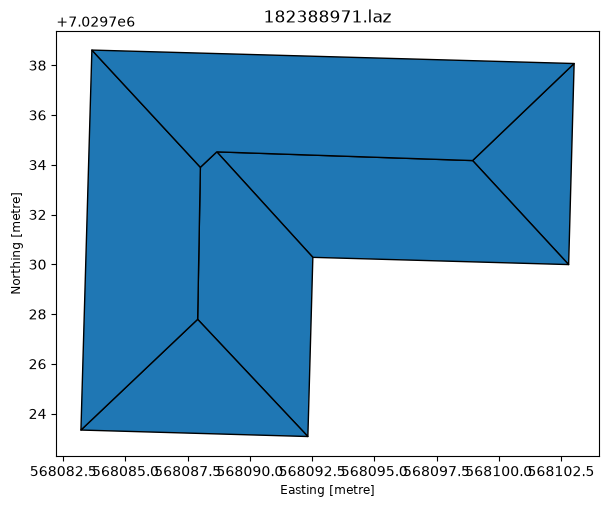

10493889.laz: 4 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


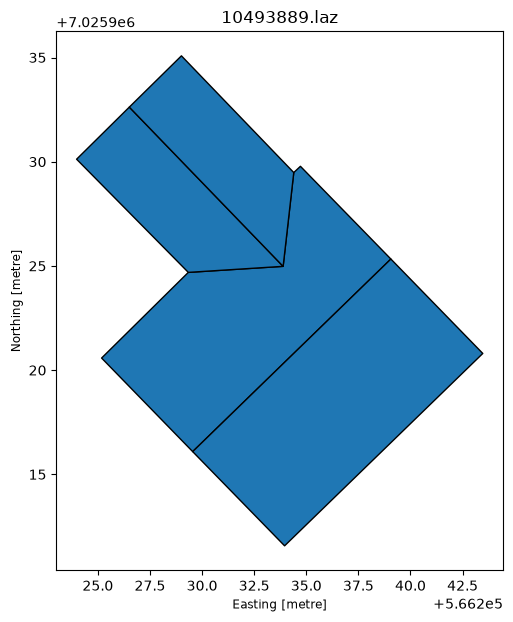

21062618.laz: 4 takflater


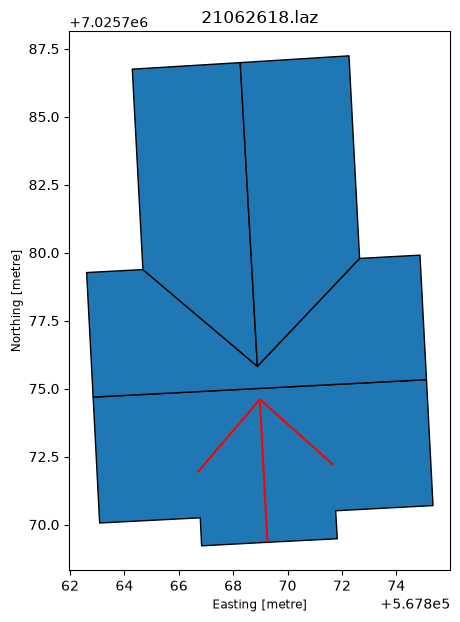

10519144.laz: 0 takflater
182251224.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


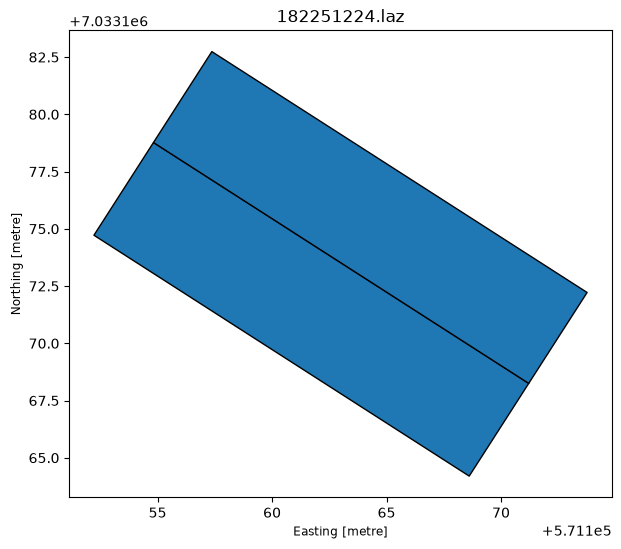

196077111.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


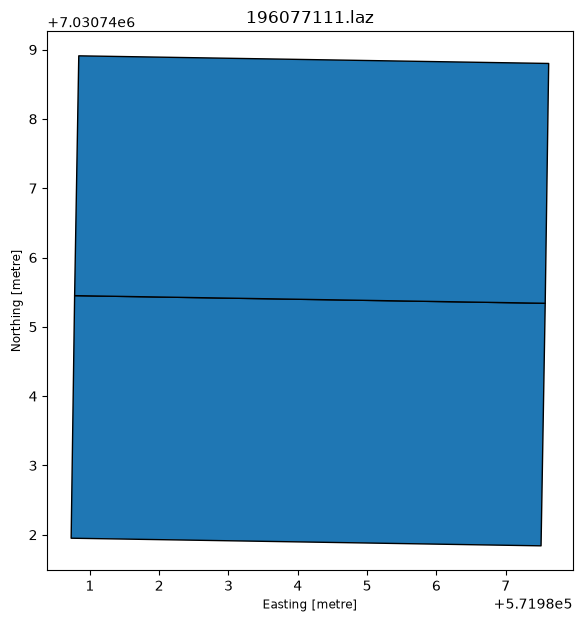

182148687.laz: 8 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


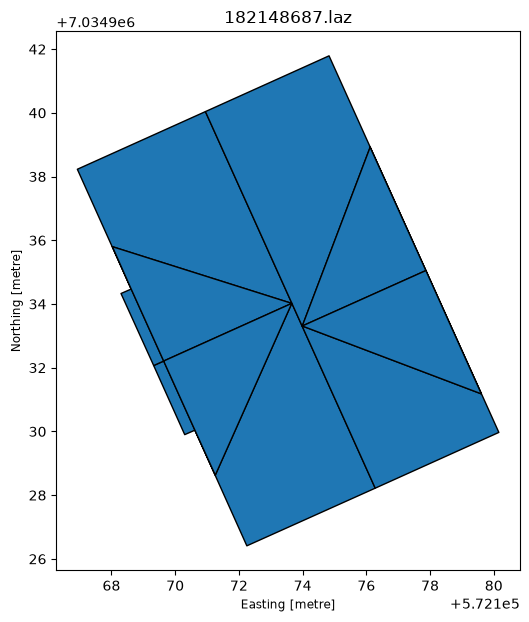

182744999.laz: 2 takflater


/var/folders/6y/bvkwrhk51k343rp58fnj1dpc0000gn/T/ipykernel_38773/1174709762.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  dangels.plot(ax = ax, color="red")


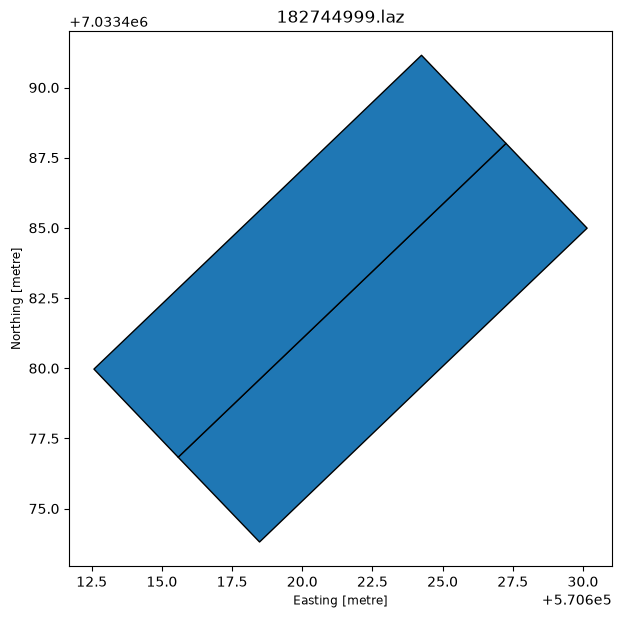

182703230.laz: 4 takflater


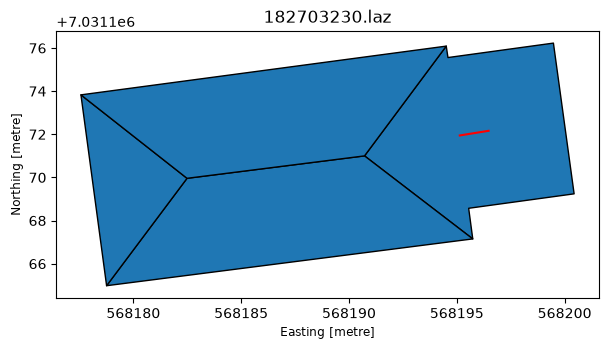

182286796.laz: 3 takflater


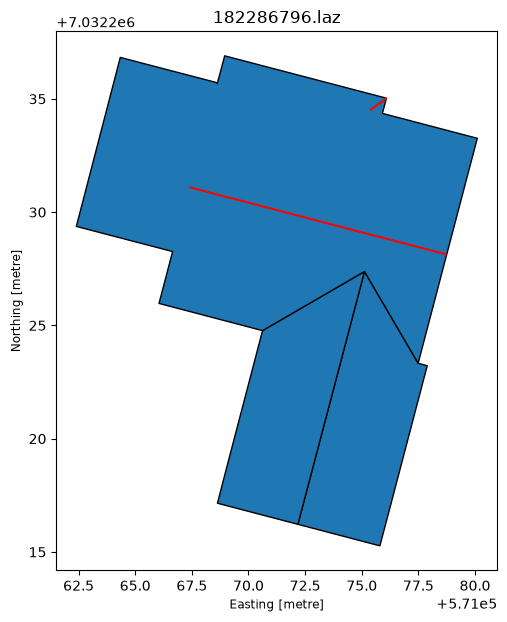

In [7]:
import matplotlib.pyplot as plt

segmentert_per_laz = {}

for laz, items in filtered_fkb.items():
    segmentering, dangels = segment_rooftiles(
        monelinje=items["monelinje"],
        takkant=items["takkant"],
        bygningslinje=items["bygningslinje"],
        tolerance=0.54,
    )
    segmentert_per_laz[laz] = segmentering
    print(f"{laz}: {len(segmentering)} takflater")

    if not segmentering.empty:
        fig, ax = plt.subplots(figsize=(7, 7))
        dangels.plot(ax = ax, color="red")
        segmentering.plot(ax = ax ,edgecolor="black")
        plt.title(laz)
        plt.show()